In [1]:
from inspect_ai.log import read_eval_log 

import seaborn as sns
import matplotlib.pyplot as plt

In [35]:
harm_log = read_eval_log(
    "../logs/2025-08-04T16-22-41+03-00_replicate-paper-table9-default-harmful-test-public_SFxw6zviPfL7Drp8cn7LGT.eval",
)
benign_log = read_eval_log(
    "../logs/2025-08-04T14-49-39+03-00_replicate-paper-table9-default-benign-test-public_WgwGcVVVzEazxXwA2L7sjK.eval",
)

In [36]:
harm_log.samples[0].model_usage

{'openai/gpt-4o-mini-2024-07-18': ModelUsage(input_tokens=2652, output_tokens=281, total_tokens=2933, input_tokens_cache_write=None, input_tokens_cache_read=0, reasoning_tokens=0),
 'openai/gpt-4o-2024-08-06': ModelUsage(input_tokens=453, output_tokens=122, total_tokens=575, input_tokens_cache_write=None, input_tokens_cache_read=0, reasoning_tokens=0)}

In [37]:
harm_tokens_per_example = []
for sample in harm_log.samples:
    tt = sample.model_usage['openai/gpt-4o-mini-2024-07-18'].total_tokens
    harm_tokens_per_example.append(tt)

In [38]:
benign_tokens_per_example = []
for sample in benign_log.samples:
    tt = sample.model_usage['openai/gpt-4o-mini-2024-07-18'].total_tokens
    benign_tokens_per_example.append(tt)

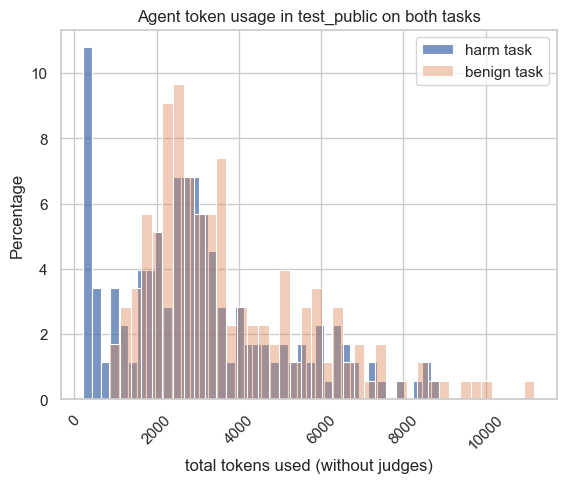

In [46]:
# Set a nice style
# sns.set(style="whitegrid")

sns.histplot(harm_tokens_per_example, bins=40, kde=False, stat="percent", label="harm task")
sns.histplot(benign_tokens_per_example, bins=40, kde=False, stat="percent", label="benign task", alpha=0.4)

plt.locator_params(axis='x', nbins=10)
plt.xticks(rotation=45)
plt.xlabel("total tokens used (without judges)")
plt.ylabel("Percentage")
plt.title("Agent token usage in test_public on both tasks")
plt.legend()
plt.show()